## CNN for CIFAR-10 Image Classification



## 1. Import required libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random
import tensorflow as tf

from tensorflow.keras import datasets, layers, models
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

d:\Damodarone\Python\venv\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


## 2. Load the CIFAR-10 dataset

In [2]:
(X_train, y_train), (X_test, y_test) = datasets.cifar10.load_data()

## 3. Check the dataset shape

In [3]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (50000, 32, 32, 3)
y_train shape: (50000, 1)
X_test shape: (10000, 32, 32, 3)
y_test shape: (10000, 1)


## 4. Define the class names

In [4]:
class_names = [
    'airplane',
    'automobile',
    'bird',
    'cat',
    'deer',
    'dog',
    'frog',
    'horse',
    'ship',
    'truck'
]

## 5. Display a sample image

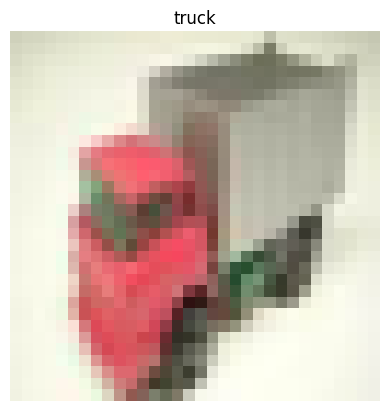

In [5]:
idx = random.randrange(len(X_train))

plt.imshow(X_train[idx])
plt.title(class_names[y_train[idx][0]])
plt.axis('off')
plt.show()

## 6. Normalize the image data

In [6]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [7]:
print(X_train.shape)
print(X_test.shape)

(50000, 32, 32, 3)
(10000, 32, 32, 3)


## 7. Build the CNN model

In [ ]:
model = Sequential()

model.add(Conv2D(32, (3, 3), activation='relu',
                 input_shape=(32, 32, 3)))

model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(64, (3, 3), activation='relu'))

model.add(MaxPooling2D((2, 2)))

model.add(Flatten())

model.add(Dense(64, activation='relu'))

model.add(Dense(10, activation='softmax'))

## 8. Compile the model

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## 9. Display model summary

In [ ]:
model.summary()

## 10. Train the model

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=2,
    validation_data=(X_test, y_test)
)

## 11. Evaluate the model

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

## 12. Plot training and validation accuracy

In [ ]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Model Accuracy')

plt.legend()
plt.show()

## 13. Plot training and validation loss

In [ ]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Model Loss')

plt.legend()
plt.show()

## 14. Predict a random test image

In [ ]:
idx2 = random.randrange(len(X_test))

plt.imshow(X_test[idx2])
plt.axis('off')
plt.show()

y_pred = model.predict(X_test[idx2:idx2 + 1], verbose=0)

pred = class_names[np.argmax(y_pred[0])]

print('Our model says it is a:', pred)

## 15. Display actual and predicted labels

In [ ]:
actual = class_names[y_test[idx2][0]]

print("Actual image:", actual)
print("Predicted image:", pred)